In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# =============================================================================
# 2. CONFIGURAÇÕES E CONSTANTES GLOBAIS
# =============================================================================
ANOS = [2022, 2023, 2024, 2025]
CAMINHO = '/content/SPDadosCriminais_GERAL.csv'
CAMINHO_POPULACAO = '/content/populacao_municipiosSP.csv'



df = pd.read_csv(CAMINHO, sep=',', encoding='utf-8-sig', low_memory=False)

print(f"-> Dimensões finais do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")
df.head()

-> Dimensões finais do dataset: 813622 linhas e 16 colunas



,NOME_MUNICIPIO,ANO_BO,DATA_REGISTRO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA_BO,DESC_PERIODO,DESCR_SUBTIPOLOCAL,BAIRRO,LOGRADOURO,NUMERO_LOGRADOURO,LATITUDE,LONGITUDE,RUBRICA,DESCR_CONDUTA,NATUREZA_APURADA,CD_IBGE
0,SAO PAULO,2022.0,2022-01-16 00:00:00,2022-01-16,10:00:00,NaN,Via pública,Liberdade,Rua Barão de Iguape,435,-23.5581952,-46.6320429,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308
1,SAO PAULO,2022.0,2022-01-08 00:00:00,2022-01-08,12:30:00,NaN,Via pública,SE,RUA CAVALHEIRO BASILIO JAFET,999999999,-23.5441800909999,-46.631058943,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308
2,SAO PAULO,2022.0,2022-01-12 00:00:00,2022-01-12,06:50:00,NaN,Via pública,SE,AVENIDA DO ESTADO,2800,-23.5501638709999,-46.626634281,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308
3,SAO PAULO,2022.0,2022-01-16 00:00:00,2022-01-16,10:35:00,NaN,Via pública,SE,RUA JORGE AZEM,18,-23.545574772,-46.631622154,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308
4,SAO PAULO,2022.0,2022-01-19 00:00:00,2022-01-19,08:00:00,NaN,Via pública,SE,RUA TABATINGUERA,63,-23.552163255,-46.627577217,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308


In [2]:
# Tratamento da Data
# Coerce transforma erros (como datas 31/02) em NaT (Not a Time)
df['DATA'] = pd.to_datetime(df['DATA_OCORRENCIA_BO'], errors='coerce')

# Extraindo dia da semana (0 = Segunda, 6 = Domingo)
df['DIA_SEMANA'] = df['DATA'].dt.dayofweek

# Mapeando para nomes em português para o gráfico
dias_map = {0: 'Segunda', 1: 'Terça', 2: 'Quarta', 3: 'Quinta', 4: 'Sexta', 5: 'Sábado', 6: 'Domingo'}
df['NOME_DIA_SEMANA'] = df['DIA_SEMANA'].map(dias_map)

# Tratamento da Hora
# Remove espaços, preenche nulos temporariamente e extrai apenas a hora (antes do ':')
df['HORA_LIMPA'] = df['HORA_OCORRENCIA_BO'].astype(str).str.strip().str.split(':').str[0]

# Converte para numérico, transformando sujeiras em NaN
df['HORA_INT'] = pd.to_numeric(df['HORA_LIMPA'], errors='coerce')

# Filtra horas válidas (0 a 23) E 'NOME_DIA_SEMANA' não nulo para garantir grupos válidos para o heatmap
df_heatmap = df[
    (df['HORA_INT'] >= 0) & (df['HORA_INT'] <= 23) &
    (df['NOME_DIA_SEMANA'].notna())
].copy()

print(f'-> Dimensões finais do dataset: {df_heatmap.shape[0]} linhas. Foram removidas {df.shape[0] - df_heatmap.shape[0]} linhas sem horário registrado.')

-> Dimensões finais do dataset: 813167 linhas. Foram removidas 455 linhas sem horário registrado.


In [3]:
import numpy as np

# Criando um filtro para remover linhas onde LATITUDE e LONGITUDE são iguais a 0 (ou nulas/inválidas)
linhas_com_coordenadas_zero = (df['LATITUDE'] == 0) & (df['LONGITUDE'] == 0)

# Dataset sem localizações zeradas
df_sem_loc = df[~linhas_com_coordenadas_zero].copy()
df_sem_loc = df_sem_loc['LATITUDE'].notna()

linhas_removidas = df.shape[0] - df_sem_loc.shape[0]

print(f'-> Dimensões finais do dataset: {df_sem_loc.shape[0]} linhas. Foram removidas {linhas_removidas} linhas com latitude e longitude nula.')

-> Dimensões finais do dataset: 813622 linhas. Foram removidas 0 linhas com latitude e longitude nula.


### 1. Definição do Alvo e Preparação dos Dados para o MLP
Para aplicar o classificador, primeiro precisamos reconstruir corretamente a variável `df_sem_loc` como um DataFrame (corrigindo a atribuição anterior que a transformou em Series booleana) e definir nossa variável resposta (Target). Vamos definir áreas perigosas (1) como aquelas que possuem uma densidade de crimes acima da mediana histórica.

# Pipeline Corrigido e Otimizado de Classificação de Risco com MLP

Este pipeline foi revisado para corrigir problemas de **vazamento de dados (Data Leakage)** e **redundância de recursos espaciais**.

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Limpeza Inicial de Dados e Remoção de Coordenadas Nulas/Inválidas
df['LAT_NUM'] = pd.to_numeric(df['LATITUDE'], errors='coerce')
df['LON_NUM'] = pd.to_numeric(df['LONGITUDE'], errors='coerce')

df_limpo = df[df['LAT_NUM'].notna() & df['LON_NUM'].notna() & (df['LAT_NUM'] != 0) & (df['LON_NUM'] != 0)].copy()
df_limpo['LATITUDE'] = df_limpo['LAT_NUM']
df_limpo['LONGITUDE'] = df_limpo['LON_NUM']

# Tratamento temporal
df_limpo['HORA_LIMPA'] = df_limpo['HORA_OCORRENCIA_BO'].astype(str).str.strip().str.split(':').str[0]
df_limpo['HORA_INT'] = pd.to_numeric(df_limpo['HORA_LIMPA'], errors='coerce').fillna(12)
df_limpo['DATA_DT'] = pd.to_datetime(df_limpo['DATA_OCORRENCIA_BO'], errors='coerce')
df_limpo['DIA_SEMANA'] = df_limpo['DATA_DT'].dt.dayofweek.fillna(0)

# Amostragem para viabilidade computacional rápida (300.000 amostras)
if len(df_limpo) > 300000:
    df_sample = df_limpo.sample(n=300000, random_state=42).copy()
else:
    df_sample = df_limpo.copy()

# 2. Divisão Estrita de Treino e Teste ANTES da Engenharia de Alvo (Evita Vazamento de Dados)
df_train, df_test = train_test_split(df_sample, test_size=0.30, random_state=42)

In [5]:
# 3. Engenharia do Alvo Baseada Apenas no Conjunto de Treino
df_train['LAT_ROUND'] = df_train['LATITUDE'].round(2)
df_train['LON_ROUND'] = df_train['LONGITUDE'].round(2)
df_test['LAT_ROUND'] = df_test['LATITUDE'].round(2)
df_test['LON_ROUND'] = df_test['LONGITUDE'].round(2)

# Calcula frequências com base unicamente no treino
contagem_zona_treino = df_train.groupby(['LAT_ROUND', 'LON_ROUND']).size().reset_index(name='FREQ_CRIMES_TREINO')

# Mediana unicamente do treino para determinar o limiar de risco
limiar_perigo = contagem_zona_treino['FREQ_CRIMES_TREINO'].median()

# Mapeando de volta ao conjunto de Treino
df_train = pd.merge(df_train, contagem_zona_treino, on=['LAT_ROUND', 'LON_ROUND'], how='left')
df_train['LOCAL_PERIGOSO'] = (df_train['FREQ_CRIMES_TREINO'] > limiar_perigo).astype(int)

# Mapeando ao conjunto de Teste (Evitando o vazamento)
df_test = pd.merge(df_test, contagem_zona_treino, on=['LAT_ROUND', 'LON_ROUND'], how='left')
df_test['FREQ_CRIMES_TREINO'] = df_test['FREQ_CRIMES_TREINO'].fillna(0)
df_test['LOCAL_PERIGOSO'] = (df_test['FREQ_CRIMES_TREINO'] > limiar_perigo).astype(int)

print("Distribuição de Classes no Treino:", np.bincount(df_train['LOCAL_PERIGOSO']))
print("Distribuição de Classes no Teste:", np.bincount(df_test['LOCAL_PERIGOSO']))

Distribuição de Classes no Treino: [ 7756 62244]
Distribuição de Classes no Teste: [ 4262 25738]


In [6]:
# 4. Engenharia de Recursos Espaciais Sem Redundâncias Categóricas
# Projeção esférica tridimensional
for dataset in [df_train, df_test]:
    lat_rad = np.radians(dataset['LATITUDE'])
    lon_rad = np.radians(dataset['LONGITUDE'])
    dataset['COORD_X'] = np.cos(lat_rad) * np.cos(lon_rad)
    dataset['COORD_Y'] = np.cos(lat_rad) * np.sin(lon_rad)
    dataset['COORD_Z'] = np.sin(lat_rad)

# Clusterização espacial usando apenas informações de treino para ajustar o KMeans
kmeans = KMeans(n_clusters=8, random_state=42, n_init=5)
kmeans.fit(df_train[['LATITUDE', 'LONGITUDE']])

# Adicionando as distâncias contínuas calculadas
train_dists = kmeans.transform(df_train[['LATITUDE', 'LONGITUDE']])
test_dists = kmeans.transform(df_test[['LATITUDE', 'LONGITUDE']])

for i in range(8):
    df_train[f'DIST_C{i}'] = train_dists[:, i]
    df_test[f'DIST_C{i}'] = test_dists[:, i]

# Definindo os novos conjuntos de recursos limpos de multicolinearidade
features_limpas = ['COORD_X', 'COORD_Y', 'COORD_Z', 'HORA_INT', 'DIA_SEMANA'] + [f'DIST_C{i}' for i in range(8)]

X_train_p = df_train[features_limpas]
y_train_p = df_train['LOCAL_PERIGOSO']

X_test_p = df_test[features_limpas]
y_test_p = df_test['LOCAL_PERIGOSO']

# Escalonamento adequado
scaler_p = StandardScaler()
X_train_p_scaled = scaler_p.fit_transform(X_train_p)
X_test_p_scaled = scaler_p.transform(X_test_p)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (8). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


In [7]:
# 5. Treinamento e Avaliação do Modelo Otimizado Sem Vazamentos
mlp_final = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    alpha=0.0001,
    learning_rate_init=0.01,
    max_iter=50,
    random_state=42,
    verbose=True
)

mlp_final.fit(X_train_p_scaled, y_train_p)
y_pred_p = mlp_final.predict(X_test_p_scaled)

print("\n" + "="*50)
print("DESEMPENHO DO MODELO AJUSTADO (SEM DATA LEAKAGE)")
print("="*50)
print(f"Acurácia Final no Teste: {accuracy_score(y_test_p, y_pred_p):.4f}\n")
print(classification_report(y_test_p, y_pred_p))

Iteration 1, loss = 0.29860720
Iteration 2, loss = 0.27701297
Iteration 3, loss = 0.27187605
Iteration 4, loss = 0.26838695
Iteration 5, loss = 0.26635887
Iteration 6, loss = 0.26270350
Iteration 7, loss = 0.26208978
Iteration 8, loss = 0.26070477
Iteration 9, loss = 0.25979918
Iteration 10, loss = 0.25847942
Iteration 11, loss = 0.25896058
Iteration 12, loss = 0.25812995
Iteration 13, loss = 0.25701414
Iteration 14, loss = 0.25682197
Iteration 15, loss = 0.25694131
Iteration 16, loss = 0.25640125
Iteration 17, loss = 0.25589176
Iteration 18, loss = 0.25567129
Iteration 19, loss = 0.25546212
Iteration 20, loss = 0.25461032
Iteration 21, loss = 0.25470958
Iteration 22, loss = 0.25358369
Iteration 23, loss = 0.25424923
Iteration 24, loss = 0.25354863
Iteration 25, loss = 0.25262861
Iteration 26, loss = 0.25297506
Iteration 27, loss = 0.25268616
Iteration 28, loss = 0.25304071
Iteration 29, loss = 0.25266033
Iteration 30, loss = 0.25201662
Iteration 31, loss = 0.25241970
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


### 9. Pipeline Consolidado e Corrigido (Sem Vazamentos e Balanceado)
Este bloco executa a limpeza, divisão estrita, engenharia de alvos balanceada (evitando vazamento de dados), projeção 3D de coordenadas e o treinamento do classificador MLP final com visualização gráfica.

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparação e Amostragem Balanceada Computacional
df_limpo = df.copy()
df_limpo['LAT_NUM'] = pd.to_numeric(df_limpo['LATITUDE'], errors='coerce')
df_limpo['LON_NUM'] = pd.to_numeric(df_limpo['LONGITUDE'], errors='coerce')
df_limpo = df_limpo[df_limpo['LAT_NUM'].notna() & df_limpo['LON_NUM'].notna() & (df_limpo['LAT_NUM'] != 0) & (df_limpo['LON_NUM'] != 0)].copy()

# Tratamento temporal
df_limpo['HORA_LIMPA'] = df_limpo['HORA_OCORRENCIA_BO'].astype(str).str.strip().str.split(':').str[0]
df_limpo['HORA_INT'] = pd.to_numeric(df_limpo['HORA_LIMPA'], errors='coerce').fillna(12)
df_limpo['DATA_DT'] = pd.to_datetime(df_limpo['DATA_OCORRENCIA_BO'], errors='coerce')
df_limpo['DIA_SEMANA'] = df_limpo['DATA_DT'].dt.dayofweek.fillna(0)

# Redução para 100.000 amostras aleatórias
if len(df_limpo) > 100000:
    df_sample = df_limpo.sample(n=100000, random_state=42).copy()
else:
    df_sample = df_limpo.copy()

# 2. Divisão Estrita de Treino (70%) e Teste (30%)
df_train, df_test = train_test_split(df_sample, test_size=0.30, random_state=42)

# Arredondamento para blocos
df_train['LAT_ROUND'] = df_train['LAT_NUM'].round(2)
df_train['LON_ROUND'] = df_train['LON_NUM'].round(2)
df_test['LAT_ROUND'] = df_test['LAT_NUM'].round(2)
df_test['LON_ROUND'] = df_test['LON_NUM'].round(2)

# 3. Engenharia de Alvo Balanceada (Sem Vazamento de Informações)
contagem_zona = df_train.groupby(['LAT_ROUND', 'LON_ROUND']).size().reset_index(name='FREQ_CRIMES')
df_train = pd.merge(df_train, contagem_zona, on=['LAT_ROUND', 'LON_ROUND'], how='left')

# Definimos o limiar de perigo sobre a mediana das ocorrências individuais de treino
limiar_perigo_balanceado = df_train['FREQ_CRIMES'].median()
df_train['LOCAL_PERIGOSO'] = (df_train['FREQ_CRIMES'] > limiar_perigo_balanceado).astype(int)

# Mapeamos o conjunto de teste de forma estritamente cega usando o que foi aprendido no treino
df_test = pd.merge(df_test, contagem_zona, on=['LAT_ROUND', 'LON_ROUND'], how='left')
df_test['FREQ_CRIMES'] = df_test['FREQ_CRIMES'].fillna(0)
df_test['LOCAL_PERIGOSO'] = (df_test['FREQ_CRIMES'] > limiar_perigo_balanceado).astype(int)

print("Distribuição Balanceada de Classes (Treino):", np.bincount(df_train['LOCAL_PERIGOSO']))
print("Distribuição Balanceada de Classes (Teste):", np.bincount(df_test['LOCAL_PERIGOSO']))

Distribuição Balanceada de Classes (Treino): [35798 34202]
Distribuição Balanceada de Classes (Teste): [15819 14181]


In [9]:
# 4. Conversão para Coordenadas 3D Esféricas e Escalonamento
for dataset in [df_train, df_test]:
    lat_rad = np.radians(dataset['LAT_NUM'])
    lon_rad = np.radians(dataset['LON_NUM'])
    dataset['COORD_X'] = np.cos(lat_rad) * np.cos(lon_rad)
    dataset['COORD_Y'] = np.cos(lat_rad) * np.sin(lon_rad)
    dataset['COORD_Z'] = np.sin(lat_rad)

features_finais = ['COORD_X', 'COORD_Y', 'COORD_Z', 'HORA_INT', 'DIA_SEMANA']

X_train_f = df_train[features_finais]
y_train_f = df_train['LOCAL_PERIGOSO']
X_test_f = df_test[features_finais]
y_test_f = df_test['LOCAL_PERIGOSO']

scaler_f = StandardScaler()
X_train_scaled_f = scaler_f.fit_transform(X_train_f)
X_test_scaled_f = scaler_f.transform(X_test_f)

In [10]:
# 5. Treinamento e Avaliação da Rede MLP Otimizada
mlp_final = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    alpha=0.0001,
    learning_rate_init=0.01,
    max_iter=50,
    random_state=42,
    verbose=True
)

mlp_final.fit(X_train_scaled_f, y_train_f)
y_pred_f = mlp_final.predict(X_test_scaled_f)

print("\n" + "="*50)
print("DESEMPENHO DO MODELO CORRIGIDO E TOTALMENTE BALANCEADO")
print("="*50)
print(f"Acurácia Geral: {accuracy_score(y_test_f, y_pred_f):.4f}\n")
print(classification_report(y_test_f, y_pred_f))

Iteration 1, loss = 0.49502236
Iteration 2, loss = 0.45928459
Iteration 3, loss = 0.45170587
Iteration 4, loss = 0.44639717
Iteration 5, loss = 0.44237128
Iteration 6, loss = 0.44014962
Iteration 7, loss = 0.43846177
Iteration 8, loss = 0.43613045
Iteration 9, loss = 0.43514427
Iteration 10, loss = 0.43313871
Iteration 11, loss = 0.43048954
Iteration 12, loss = 0.43023719
Iteration 13, loss = 0.42818767
Iteration 14, loss = 0.42648234
Iteration 15, loss = 0.42570725
Iteration 16, loss = 0.42510334
Iteration 17, loss = 0.42377133
Iteration 18, loss = 0.42138195
Iteration 19, loss = 0.42046799
Iteration 20, loss = 0.41887003
Iteration 21, loss = 0.42026425
Iteration 22, loss = 0.41776445
Iteration 23, loss = 0.41769708
Iteration 24, loss = 0.41685269
Iteration 25, loss = 0.41458367
Iteration 26, loss = 0.41596082
Iteration 27, loss = 0.41446302
Iteration 28, loss = 0.41291611
Iteration 29, loss = 0.41096722
Iteration 30, loss = 0.41241375
Iteration 31, loss = 0.40917124
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


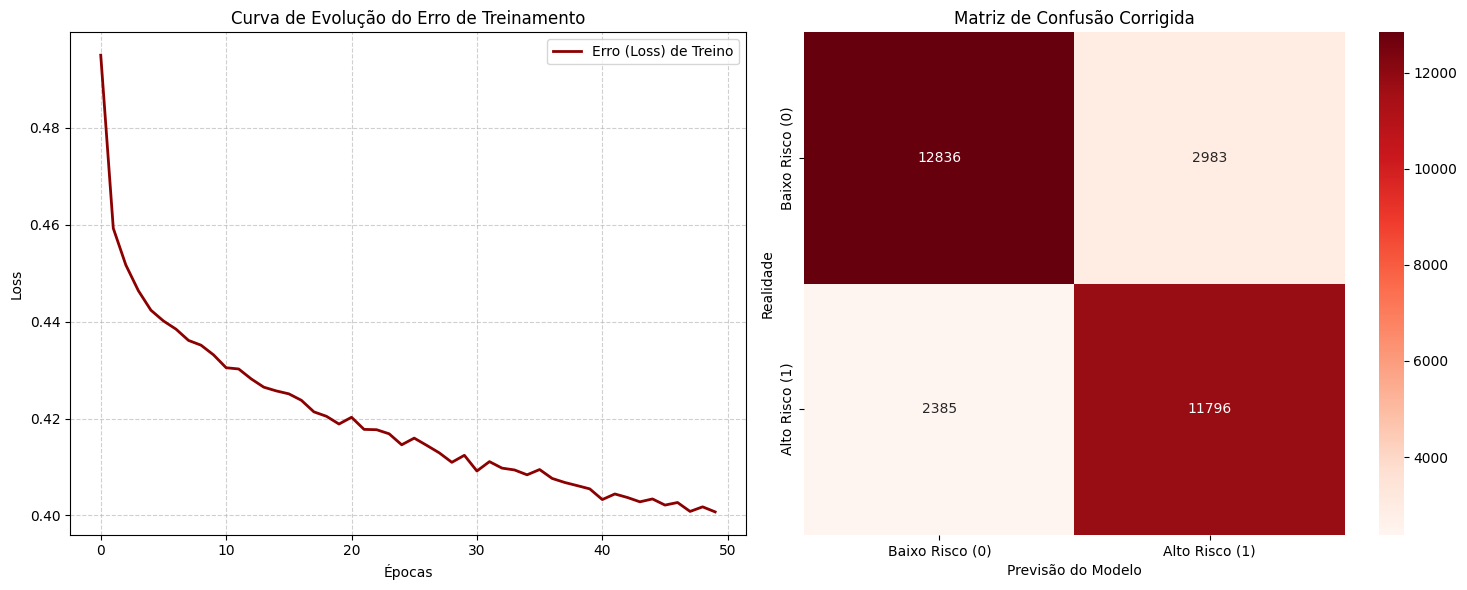

In [11]:
# 6. Geração dos Gráficos de Evolução de Erro e Performance de Classificação
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Curva de Perda (Loss)
axes[0].plot(mlp_final.loss_curve_, color='darkred', lw=2, label='Erro (Loss) de Treino')
axes[0].set_title('Curva de Evolução do Erro de Treinamento')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Matriz de Confusão
cm_f = confusion_matrix(y_test_f, y_pred_f)
sns.heatmap(cm_f, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            xticklabels=['Baixo Risco (0)', 'Alto Risco (1)'],
            yticklabels=['Baixo Risco (0)', 'Alto Risco (1)'])
axes[1].set_title('Matriz de Confusão Corrigida')
axes[1].set_ylabel('Realidade')
axes[1].set_xlabel('Previsão do Modelo')

plt.tight_layout()
plt.show()

### 9. Pipeline Consolidado e Corrigido (Sem Vazamentos e Balanceado)
Este bloco executa a limpeza, divisão estrita, engenharia de alvos balanceada (evitando vazamento de dados), projeção 3D de coordenadas e o treinamento do classificador MLP final com visualização gráfica.

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparação e Amostragem Balanceada Computacional
df_limpo = df.copy()
df_limpo['LAT_NUM'] = pd.to_numeric(df_limpo['LATITUDE'], errors='coerce')
df_limpo['LON_NUM'] = pd.to_numeric(df_limpo['LONGITUDE'], errors='coerce')
df_limpo = df_limpo[df_limpo['LAT_NUM'].notna() & df_limpo['LON_NUM'].notna() & (df_limpo['LAT_NUM'] != 0) & (df_limpo['LON_NUM'] != 0)].copy()

# Tratamento temporal
df_limpo['HORA_LIMPA'] = df_limpo['HORA_OCORRENCIA_BO'].astype(str).str.strip().str.split(':').str[0]
df_limpo['HORA_INT'] = pd.to_numeric(df_limpo['HORA_LIMPA'], errors='coerce').fillna(12)
df_limpo['DATA_DT'] = pd.to_datetime(df_limpo['DATA_OCORRENCIA_BO'], errors='coerce')
df_limpo['DIA_SEMANA'] = df_limpo['DATA_DT'].dt.dayofweek.fillna(0)

# Redução para 100.000 amostras aleatórias
if len(df_limpo) > 100000:
    df_sample = df_limpo.sample(n=100000, random_state=42).copy()
else:
    df_sample = df_limpo.copy()

# 2. Divisão Estrita de Treino (70%) e Teste (30%)
df_train, df_test = train_test_split(df_sample, test_size=0.30, random_state=42)

# Arredondamento para blocos
df_train['LAT_ROUND'] = df_train['LAT_NUM'].round(2)
df_train['LON_ROUND'] = df_train['LON_NUM'].round(2)
df_test['LAT_ROUND'] = df_test['LAT_NUM'].round(2)
df_test['LON_ROUND'] = df_test['LON_NUM'].round(2)

# 3. Engenharia de Alvo Balanceada (Sem Vazamento de Informações)
contagem_zona = df_train.groupby(['LAT_ROUND', 'LON_ROUND']).size().reset_index(name='FREQ_CRIMES')
df_train = pd.merge(df_train, contagem_zona, on=['LAT_ROUND', 'LON_ROUND'], how='left')

# Definimos o limiar de perigo sobre a mediana das ocorrências individuais de treino
limiar_perigo_balanceado = df_train['FREQ_CRIMES'].median()
df_train['LOCAL_PERIGOSO'] = (df_train['FREQ_CRIMES'] > limiar_perigo_balanceado).astype(int)

# Mapeamos o conjunto de teste de forma estritamente cega usando o que foi aprendido no treino
df_test = pd.merge(df_test, contagem_zona, on=['LAT_ROUND', 'LON_ROUND'], how='left')
df_test['FREQ_CRIMES'] = df_test['FREQ_CRIMES'].fillna(0)
df_test['LOCAL_PERIGOSO'] = (df_test['FREQ_CRIMES'] > limiar_perigo_balanceado).astype(int)

print("Distribuição Balanceada de Classes (Treino):", np.bincount(df_train['LOCAL_PERIGOSO']))
print("Distribuição Balanceada de Classes (Teste):", np.bincount(df_test['LOCAL_PERIGOSO']))

Distribuição Balanceada de Classes (Treino): [35798 34202]
Distribuição Balanceada de Classes (Teste): [15819 14181]


In [13]:
# 4. Conversão para Coordenadas 3D Esféricas e Escalonamento
for dataset in [df_train, df_test]:
    lat_rad = np.radians(dataset['LAT_NUM'])
    lon_rad = np.radians(dataset['LON_NUM'])
    dataset['COORD_X'] = np.cos(lat_rad) * np.cos(lon_rad)
    dataset['COORD_Y'] = np.cos(lat_rad) * np.sin(lon_rad)
    dataset['COORD_Z'] = np.sin(lat_rad)

features_finais = ['COORD_X', 'COORD_Y', 'COORD_Z', 'HORA_INT', 'DIA_SEMANA']

X_train_f = df_train[features_finais]
y_train_f = df_train['LOCAL_PERIGOSO']
X_test_f = df_test[features_finais]
y_test_f = df_test['LOCAL_PERIGOSO']

scaler_f = StandardScaler()
X_train_scaled_f = scaler_f.fit_transform(X_train_f)
X_test_scaled_f = scaler_f.transform(X_test_f)

In [14]:
# 5. Treinamento e Avaliação da Rede MLP Otimizada
mlp_final = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    alpha=0.0001,
    learning_rate_init=0.01,
    max_iter=50,
    random_state=42,
    verbose=True
)

mlp_final.fit(X_train_scaled_f, y_train_f)
y_pred_f = mlp_final.predict(X_test_scaled_f)

print("\n" + "="*50)
print("DESEMPENHO DO MODELO CORRIGIDO E TOTALMENTE BALANCEADO")
print("="*50)
print(f"Acurácia Geral: {accuracy_score(y_test_f, y_pred_f):.4f}\n")
print(classification_report(y_test_f, y_pred_f))

Iteration 1, loss = 0.49502236
Iteration 2, loss = 0.45928459
Iteration 3, loss = 0.45170587
Iteration 4, loss = 0.44639717
Iteration 5, loss = 0.44237128
Iteration 6, loss = 0.44014962
Iteration 7, loss = 0.43846177
Iteration 8, loss = 0.43613045
Iteration 9, loss = 0.43514427
Iteration 10, loss = 0.43313871
Iteration 11, loss = 0.43048954
Iteration 12, loss = 0.43023719
Iteration 13, loss = 0.42818767
Iteration 14, loss = 0.42648234
Iteration 15, loss = 0.42570725
Iteration 16, loss = 0.42510334
Iteration 17, loss = 0.42377133
Iteration 18, loss = 0.42138195
Iteration 19, loss = 0.42046799
Iteration 20, loss = 0.41887003
Iteration 21, loss = 0.42026425
Iteration 22, loss = 0.41776445
Iteration 23, loss = 0.41769708
Iteration 24, loss = 0.41685269
Iteration 25, loss = 0.41458367
Iteration 26, loss = 0.41596082
Iteration 27, loss = 0.41446302
Iteration 28, loss = 0.41291611
Iteration 29, loss = 0.41096722
Iteration 30, loss = 0.41241375
Iteration 31, loss = 0.40917124
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


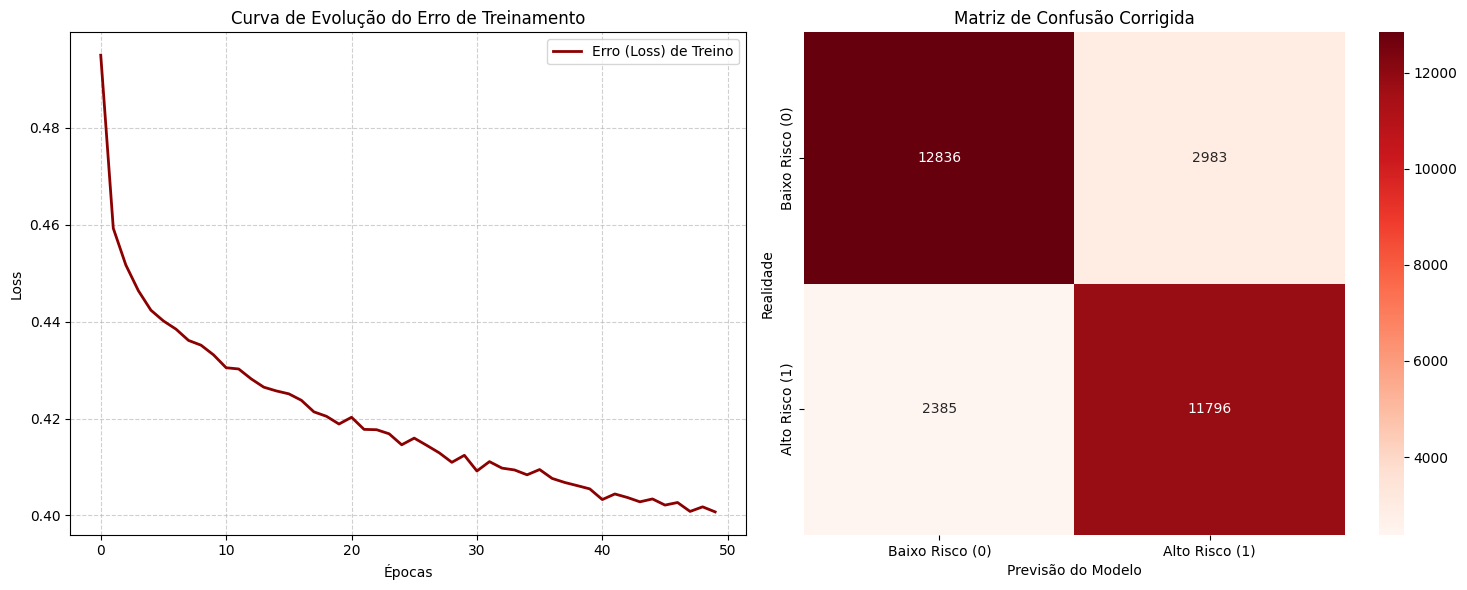

In [15]:
# 6. Geração dos Gráficos de Evolução de Erro e Performance de Classificação
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Curva de Perda (Loss)
axes[0].plot(mlp_final.loss_curve_, color='darkred', lw=2, label='Erro (Loss) de Treino')
axes[0].set_title('Curva de Evolução do Erro de Treinamento')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Matriz de Confusão
cm_f = confusion_matrix(y_test_f, y_pred_f)
sns.heatmap(cm_f, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            xticklabels=['Baixo Risco (0)', 'Alto Risco (1)'],
            yticklabels=['Baixo Risco (0)', 'Alto Risco (1)'])
axes[1].set_title('Matriz de Confusão Corrigida')
axes[1].set_ylabel('Realidade')
axes[1].set_xlabel('Previsão do Modelo')

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score
import numpy as np
import pandas as pd

# 1. Correção e reconstrução do df_sem_loc como DataFrame válido, forçando a conversão numérica das coordenadas
df['LAT_NUM'] = pd.to_numeric(df['LATITUDE'], errors='coerce')
df['LON_NUM'] = pd.to_numeric(df['LONGITUDE'], errors='coerce')

# Filtra coordenadas zeradas ou nulas de fato
linhas_com_coordenadas_zero = (df['LAT_NUM'] == 0) & (df['LON_NUM'] == 0)
df_sem_loc = df[~linhas_com_coordenadas_zero & df['LAT_NUM'].notna() & df['LON_NUM'].notna()].copy()

# Substitui as colunas originais pelas numéricas limpas
df_sem_loc['LATITUDE'] = df_sem_loc['LAT_NUM']
df_sem_loc['LONGITUDE'] = df_sem_loc['LON_NUM']

# 2. Engenharia de Recursos adicionais (Hora e Dia da semana)
# Garantindo preenchimento de horas válidas para não perder registros no treinamento
df_sem_loc['HORA_LIMPA'] = df_sem_loc['HORA_OCORRENCIA_BO'].astype(str).str.strip().str.split(':').str[0]
df_sem_loc['HORA_INT'] = pd.to_numeric(df_sem_loc['HORA_LIMPA'], errors='coerce').fillna(12) # imputação simples da mediana
df_sem_loc['DATA_DT'] = pd.to_datetime(df_sem_loc['DATA_OCORRENCIA_BO'], errors='coerce')
df_sem_loc['DIA_SEMANA'] = df_sem_loc['DATA_DT'].dt.dayofweek.fillna(0)

# 3. Definindo o Alvo de maneira balanceada no nível das ocorrências individuais
# Arredondando as coordenadas para criar pequenos blocos de vizinhança
df_sem_loc['LAT_ROUND'] = df_sem_loc['LATITUDE'].round(2)
df_sem_loc['LON_ROUND'] = df_sem_loc['LONGITUDE'].round(2)

# Calcula o volume de ocorrências por vizinhança
contagem_zona = df_sem_loc.groupby(['LAT_ROUND', 'LON_ROUND']).size().reset_index(name='FREQ_CRIMES')

# Mesclando o contador de volta para as ocorrências individuais primeiro
df_modelo = pd.merge(df_sem_loc, contagem_zona, on=['LAT_ROUND', 'LON_ROUND'], how='left')

# Agora sim, definimos o limiar como a mediana das frequências no nível de incidente individual
limiar_perigo_individual = df_modelo['FREQ_CRIMES'].median()
df_modelo['LOCAL_PERIGOSO'] = (df_modelo['FREQ_CRIMES'] > limiar_perigo_individual).astype(int)

# Seleção de variáveis de entrada (Features) e Saída (Target)
features = ['LATITUDE', 'LONGITUDE', 'HORA_INT', 'DIA_SEMANA']
X = df_modelo[features]
y = df_modelo['LOCAL_PERIGOSO'].fillna(0)

print(f"Dataset pronto! Total de amostras para o modelo: {X.shape[0]}")
print(f"Distribuição CORRIGIDA e BALANCEADA das Classes (0 = Baixo risco, 1 = Alto risco):\n{y.value_counts(normalize=True)}")



Dataset pronto! Total de amostras para o modelo: 706652
Distribuição CORRIGIDA e BALANCEADA das Classes (0 = Baixo risco, 1 = Alto risco):
LOCAL_PERIGOSO
0    0.500732
1    0.499268
Name: proportion, dtype: float64


### 2. Divisão de Treino/Teste (30/70) e Normalização
Como redes neurais artificiais (MLP) são extremamente sensíveis à escala das features de entrada, utilizaremos o `StandardScaler` após a divisão dos dados.

In [17]:
# 1. Amostragem representativa de 100.000 linhas a partir do X e y totalmente limpos e balanceados
if len(X) > 100000:
    X_sample, _, y_sample, _ = train_test_split(X, y, train_size=100000, random_state=42, stratify=y)
else:
    X_sample, y_sample = X, y

# 2. Divisão de treino (70%) e teste (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.30,
    random_state=42,
    stratify=y_sample
)

# 3. Escalonamento dos dados corrigidos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Formato dos conjuntos de dados limpos:")
print(f"-> Treino (70%): {X_train_scaled.shape[0]} amostras")
print(f"-> Teste (30%): {X_test_scaled.shape[0]} amostras")

Formato dos conjuntos de dados limpos:
-> Treino (70%): 70000 amostras
-> Teste (30%): 30000 amostras


### 3. Instanciação, Treinamento e Avaliação da Rede Neural MLP

In [18]:
# Instanciando a MLP com arquitetura padrão de 2 camadas ocultas
mlp = MLPClassifier(
    hidden_layer_sizes=(50, 25),
    activation='relu',
    solver='adam',
    max_iter=100,
    random_state=42,
    verbose=True
)

print("Iniciando o treinamento do algoritmo MLP... (isso pode levar alguns instantes)")
mlp.fit(X_train_scaled, y_train)

# Predição no conjunto de teste
y_pred = mlp.predict(X_test_scaled)

# Métricas de avaliação
print("\n" + "="*50)
print("RESULTADO DA REDE NEURAL MLP")
print("="*50)
print(f"Acurácia Geral: {accuracy_score(y_test, y_pred):.4f}\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))

Iniciando o treinamento do algoritmo MLP... (isso pode levar alguns instantes)
Iteration 1, loss = 0.69242842
Iteration 2, loss = 0.69157504
Iteration 3, loss = 0.69120967
Iteration 4, loss = 0.69110828
Iteration 5, loss = 0.69095087
Iteration 6, loss = 0.69086112
Iteration 7, loss = 0.69071410
Iteration 8, loss = 0.69067442
Iteration 9, loss = 0.69060830
Iteration 10, loss = 0.69033631
Iteration 11, loss = 0.69036191
Iteration 12, loss = 0.69038009
Iteration 13, loss = 0.69020978
Iteration 14, loss = 0.69021486
Iteration 15, loss = 0.69020659
Iteration 16, loss = 0.69015100
Iteration 17, loss = 0.69016943
Iteration 18, loss = 0.69012019
Iteration 19, loss = 0.69007148
Iteration 20, loss = 0.68989614
Iteration 21, loss = 0.68994527
Iteration 22, loss = 0.68998336
Iteration 23, loss = 0.68997659
Iteration 24, loss = 0.69007968
Iteration 25, loss = 0.69002977
Iteration 26, loss = 0.68990619
Iteration 27, loss = 0.68999617
Iteration 28, loss = 0.68988807
Iteration 29, loss = 0.68983415
It

### 4. Validação Cruzada (Hyperparameter Tuning) e Seleção do Melhor MLP
Vamos utilizar o `GridSearchCV` para encontrar a melhor combinação de hiperparâmetros (como o tamanho das camadas ocultas e a taxa de aprendizado inicial `learning_rate_init`).

In [19]:
from sklearn.model_selection import GridSearchCV

# Definindo o espaço de parâmetros para busca
param_grid = {
    'hidden_layer_sizes': [(50, 25), (100, 50)],
    'alpha': [0.0001, 0.001],
    'learning_rate_init': [0.001, 0.01]
}

# Instanciando o classificador base
mlp_base = MLPClassifier(max_iter=50, random_state=42, solver='adam', activation='relu')

print("Iniciando a busca de hiperparâmetros com GridSearchCV (3-fold CV)... (pode levar alguns minutos)")
grid_search = GridSearchCV(estimator=mlp_base, param_grid=param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train_scaled, y_train)

print("\nMelhores parâmetros encontrados:", grid_search.best_params_)
print(f"Melhor acurácia de validação cruzada: {grid_search.best_score_:.4f}")

Iniciando a busca de hiperparâmetros com GridSearchCV (3-fold CV)... (pode levar alguns minutos)
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Melhores parâmetros encontrados: {'alpha': 0.0001, 'hidden_layer_sizes': (100, 50), 'learning_rate_init': 0.01}
Melhor acurácia de validação cruzada: 0.5336


### 5. Treinamento do Modelo Otimizado e Curva de Evolução do Erro (*Loss Curve*)
Agora, vamos extrair o melhor modelo encontrado pela busca, avaliar seu desempenho final no conjunto de teste e plotar os gráficos de evolução de perda (*loss*) e a matriz de confusão.

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Extraindo o melhor estimador
best_mlp = grid_search.best_estimator_

# Como o GridSearchCV já treina o melhor estimador no conjunto completo de treino,
# podemos avaliar diretamente no teste ou fazer um fit rápido com verbose para registrar a curva de erro
best_mlp.verbose = True
best_mlp.fit(X_train_scaled, y_train)

# Predições
y_pred_best = best_mlp.predict(X_test_scaled)

print("\n" + "="*50)
print("RESULTADO DA REDE NEURAL MLP OTIMIZADA")
print("="*50)
print(f"Acurácia Geral: {accuracy_score(y_test, y_pred_best):.4f}\n")
print(classification_report(y_test, y_pred_best))

Iteration 1, loss = 0.69323179
Iteration 2, loss = 0.69167478
Iteration 3, loss = 0.69100810
Iteration 4, loss = 0.69109532
Iteration 5, loss = 0.69089592
Iteration 6, loss = 0.69088485
Iteration 7, loss = 0.69081063
Iteration 8, loss = 0.69085311
Iteration 9, loss = 0.69078898
Iteration 10, loss = 0.69074858
Iteration 11, loss = 0.69061986
Iteration 12, loss = 0.69068465
Iteration 13, loss = 0.69060012
Iteration 14, loss = 0.69110130
Iteration 15, loss = 0.69079016
Iteration 16, loss = 0.69064976
Iteration 17, loss = 0.69069082
Iteration 18, loss = 0.69047488
Iteration 19, loss = 0.69061454
Iteration 20, loss = 0.69068268
Iteration 21, loss = 0.69043105
Iteration 22, loss = 0.69074362
Iteration 23, loss = 0.69067664
Iteration 24, loss = 0.69049085
Iteration 25, loss = 0.69053128
Iteration 26, loss = 0.69050651
Iteration 27, loss = 0.69062042
Iteration 28, loss = 0.69052877
Iteration 29, loss = 0.69048635
Training loss did not improve more than tol=0.000100 for 10 consecutive epochs. S

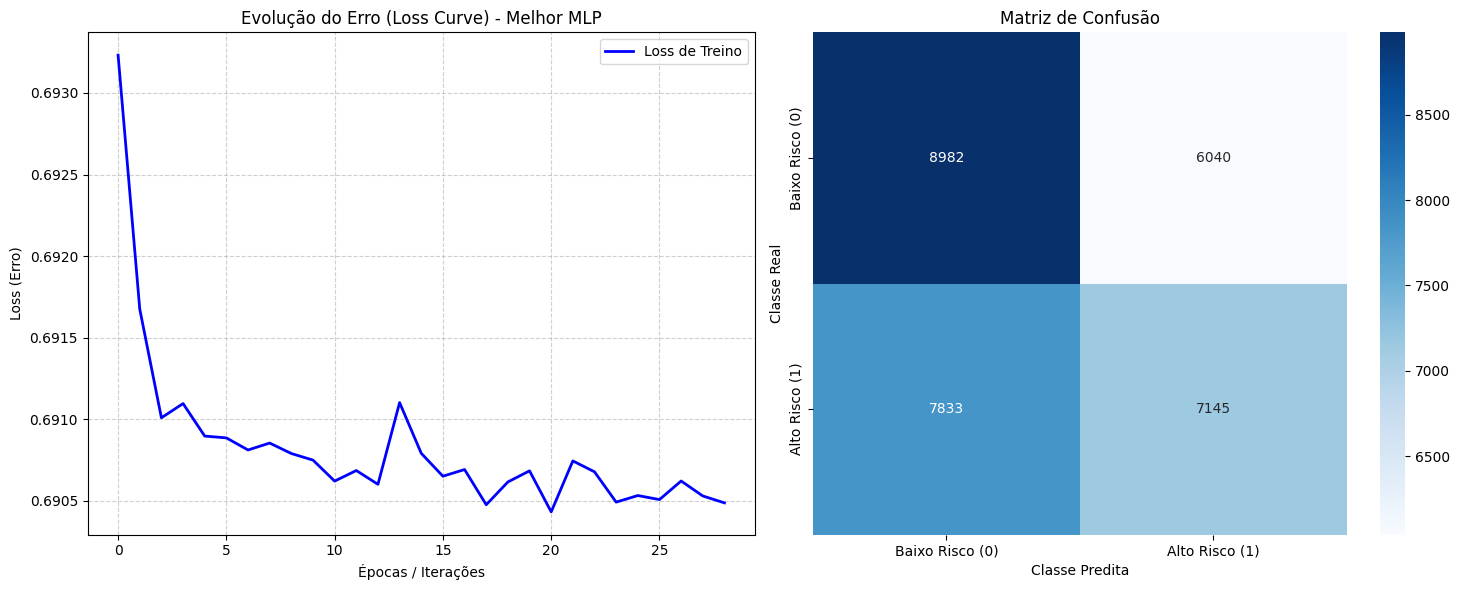

In [21]:
# Criando a figura para visualizações do Modelo
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Gráfico da curva de perda (Loss Curve)
axes[0].plot(best_mlp.loss_curve_, color='blue', lw=2, label='Loss de Treino')
axes[0].set_title('Evolução do Erro (Loss Curve) - Melhor MLP')
axes[0].set_xlabel('Épocas / Iterações')
axes[0].set_ylabel('Loss (Erro)')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# 2. Matriz de Confusão para visualizar erros e acertos
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Baixo Risco (0)', 'Alto Risco (1)'],
            yticklabels=['Baixo Risco (0)', 'Alto Risco (1)'])
axes[1].set_title('Matriz de Confusão')
axes[1].set_ylabel('Classe Real')
axes[1].set_xlabel('Classe Predita')

plt.tight_layout()
plt.show()

### 6. Extração da Importância das Features (Permutation Importance)
Como redes neurais MLP não expõem diretamente a importância das variáveis, utilizaremos a técnica de Permutação para avaliar o impacto real de cada feature no resultado do modelo.

Calculando a importância das features por permutação no conjunto de teste...


,Feature,Importance_Mean,Importance_Std
3,DIA_SEMANA,0.024400,0.002455
2,HORA_INT,0.021627,0.001936
1,LONGITUDE,0.000000,0.000000
0,LATITUDE,0.000000,0.000000


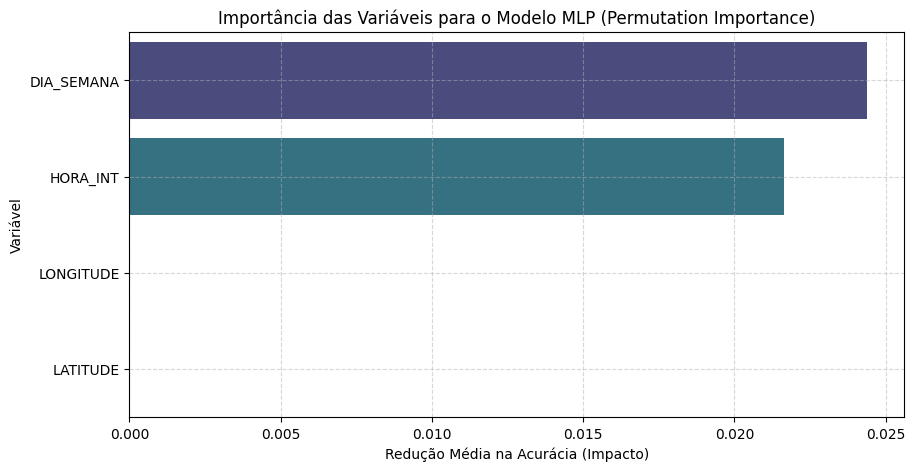

In [22]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Calculando a importância das features por permutação no conjunto de teste...")
# Calcula a importância por permutação utilizando o melhor MLP no conjunto de teste
result = permutation_importance(
    best_mlp, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

# Criando um DataFrame para organizar e visualizar os resultados
importances_df = pd.DataFrame({
    'Feature': features,
    'Importance_Mean': result.importances_mean,
    'Importance_Std': result.importances_std
}).sort_values(by='Importance_Mean', ascending=False)

display(importances_df)

# Plotando o gráfico de importância das variáveis corrigido
plt.figure(figsize=(10, 5))
sns.barplot(
    x='Importance_Mean',
    y='Feature',
    data=importances_df,
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Importância das Variáveis para o Modelo MLP (Permutation Importance)')
plt.xlabel('Redução Média na Acurácia (Impacto)')
plt.ylabel('Variável')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 7. Engenharia de Recursos Espaciais Avançada
Vamos aplicar transformações trigonométricas tridimensionais (coordenadas cartesianas) e criar clusters regionais usando KMeans para capturar de fato as relações de proximidade geográfica.

In [23]:
from sklearn.cluster import KMeans
import numpy as np

# 1. Conversão para Coordenadas Cartesianas 3D (em radianos)
lat_rad = np.radians(df_modelo['LATITUDE'])
lon_rad = np.radians(df_modelo['LONGITUDE'])

df_modelo['COORD_X'] = np.cos(lat_rad) * np.cos(lon_rad)
df_modelo['COORD_Y'] = np.cos(lat_rad) * np.sin(lon_rad)
df_modelo['COORD_Z'] = np.sin(lat_rad)

# 2. Agrupamento Espacial (KMeans para delimitar 15 regiões geográficas principais)
print("Agrupando regiões geográficas com KMeans...")
kmeans = KMeans(n_clusters=15, random_state=42, n_init=5)
df_modelo['REGIAO_CLUSTER'] = kmeans.fit_predict(df_modelo[['LATITUDE', 'LONGITUDE']])

# Criando distâncias para os centros dos clusters como features adicionais
distances = kmeans.transform(df_modelo[['LATITUDE', 'LONGITUDE']])
for i in range(15):
    df_modelo[f'DIST_CLUSTER_{i}'] = distances[:, i]

# Atualizando a lista de features utilizadas
spatial_features = ['COORD_X', 'COORD_Y', 'COORD_Z', 'REGIAO_CLUSTER'] + [f'DIST_CLUSTER_{i}' for i in range(15)]
features_atualizadas = spatial_features + ['HORA_INT', 'DIA_SEMANA']

X_novo = df_modelo[features_atualizadas]
y_novo = df_modelo['LOCAL_PERIGOSO'].fillna(0)

print(f"Novo conjunto preparado com {len(features_atualizadas)} features!")

Agrupando regiões geográficas com KMeans...
Novo conjunto preparado com 21 features!


### 8. Retreinamento e Reavaliação do MLP com Recursos Espaciais
Vamos dividir e escalonar novamente os dados para treinar um novo MLP com as features enriquecidas geograficamente.

In [24]:
# Divisão com amostragem representativa idêntica de 100.000 linhas para comparação direta
if len(X_novo) > 100000:
    X_sample_n, _, y_sample_n, _ = train_test_split(X_novo, y_novo, train_size=100000, random_state=42, stratify=y_novo)
else:
    X_sample_n, y_sample_n = X_novo, y_novo

X_train_n, X_test_n, y_train_n, y_test_n = train_test_split(
    X_sample_n, y_sample_n,
    test_size=0.30,
    random_state=42,
    stratify=y_sample_n
)

scaler_n = StandardScaler()
X_train_scaled_n = scaler_n.fit_transform(X_train_n)
X_test_scaled_n = scaler_n.transform(X_test_n)

# Treinando o MLP com os melhores hiperparâmetros encontrados anteriormente
mlp_espacial = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    alpha=0.0001,
    learning_rate_init=0.01,
    max_iter=50,
    random_state=42,
    verbose=True
)

print("Treinando o novo modelo com representações geográficas avançadas...")
mlp_espacial.fit(X_train_scaled_n, y_train_n)

y_pred_n = mlp_espacial.predict(X_test_scaled_n)
acuracia_n = accuracy_score(y_test_n, y_pred_n)

print("\n" + "="*50)
print("RESULTADO DO NOVO MLP COM ENGENHARIA ESPACIAL")
print("="*50)
print(f"Nova Acurácia Geral: {acuracia_n:.4f} (Anterior: 0.5376)\n")
print(classification_report(y_test_n, y_pred_n))

Treinando o novo modelo com representações geográficas avançadas...
Iteration 1, loss = 0.47744072
Iteration 2, loss = 0.44044387
Iteration 3, loss = 0.43520165
Iteration 4, loss = 0.43128446
Iteration 5, loss = 0.42928431
Iteration 6, loss = 0.42678198
Iteration 7, loss = 0.42421889
Iteration 8, loss = 0.42256916
Iteration 9, loss = 0.42135684
Iteration 10, loss = 0.42315469
Iteration 11, loss = 0.42052265
Iteration 12, loss = 0.41617793
Iteration 13, loss = 0.41452404
Iteration 14, loss = 0.41360141
Iteration 15, loss = 0.41413132
Iteration 16, loss = 0.41162052
Iteration 17, loss = 0.41101512
Iteration 18, loss = 0.41151230
Iteration 19, loss = 0.41124869
Iteration 20, loss = 0.41038560
Iteration 21, loss = 0.40889930
Iteration 22, loss = 0.41049070
Iteration 23, loss = 0.40807029
Iteration 24, loss = 0.40812398
Iteration 25, loss = 0.40738516
Iteration 26, loss = 0.40710607
Iteration 27, loss = 0.40602469
Iteration 28, loss = 0.40444062
Iteration 29, loss = 0.40384497
Iteration 30,

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Calculando nova importância por permutação...


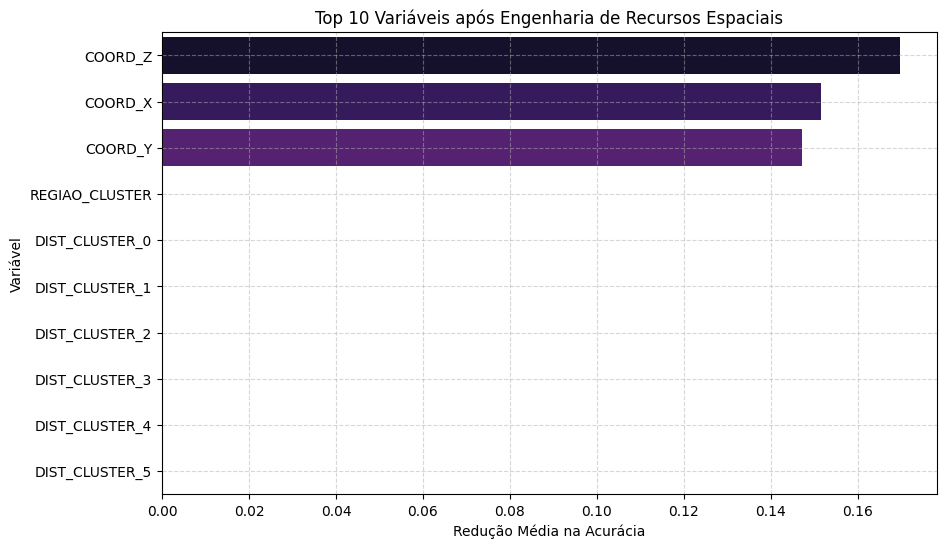

In [25]:
# Calculando e plotando a nova importância por permutação simplificada (top 10 variáveis para facilitar visualização)
print("Calculando nova importância por permutação...")
result_n = permutation_importance(
    mlp_espacial, X_test_scaled_n, y_test_n, n_repeats=5, random_state=42, n_jobs=-1
)

importances_n_df = pd.DataFrame({
    'Feature': features_atualizadas,
    'Importance_Mean': result_n.importances_mean
}).sort_values(by='Importance_Mean', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance_Mean',
    y='Feature',
    data=importances_n_df.head(10),
    hue='Feature',
    palette='magma',
    legend=False
)
plt.title('Top 10 Variáveis após Engenharia de Recursos Espaciais')
plt.xlabel('Redução Média na Acurácia')
plt.ylabel('Variável')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()